# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Muhammad Farand Danendra 
- **Email:** 2510514025@mahasiswa.upnvj.ac.id
- **ID Dicoding:** muhammad_farand

Dataset yang dipakai adalah [Bike Sharing Dataset](https://www.kaggle.com/datasets/lakshmi25npathi/bike-sharing-dataset) yang berisi data penyewaan sepeda sistem Capital Bikeshare selama tahun 2011 sampai 2012. Ada dua file yang digunakan, yaitu `day.csv` (data harian) dan `hour.csv` (data per jam).

## Menentukan Pertanyaan Bisnis

Pertanyaan bisnis disusun dengan metode **SMART** (Specific, Measurable, Action-Oriented, Relevant, Time-bound) supaya fokus analisis jelas dan hasilnya bisa langsung dipakai untuk keputusan operasional.

- **Pertanyaan 1:** Berapa rata-rata dan total penyewaan sepeda harian (`cnt`) berdasarkan kondisi cuaca (`weathersit`) dan musim (`season`) sepanjang periode 2011 sampai 2012, serta kondisi apa yang menyebabkan penurunan penyewaan terbesar?

| Unsur SMART | Penjabaran |
|---|---|
| **Specific** | Fokus pada jumlah penyewaan harian (`cnt`) yang dikelompokkan berdasarkan musim dan kondisi cuaca, lalu mencari kondisi dengan penurunan terbesar. |
| **Measurable** | Diukur dengan rata-rata dan total `cnt` per musim dan per kondisi cuaca, serta selisih persentase antar kelompok. |
| **Action-Oriented** | Hasilnya dipakai untuk menentukan kapan penyewaan turun paling banyak, sehingga tim operasional bisa menjadwalkan perawatan armada dan menyiapkan promo di waktu yang tepat. |
| **Relevant** | Cuaca dan musim memengaruhi permintaan, sehingga relevan untuk perencanaan jumlah sepeda dan pendapatan. |
| **Time-bound** | Data harian 1 Januari 2011 sampai 31 Desember 2012. |

- **Pertanyaan 2:** Pada jam (`hr`) berapa terjadi puncak tertinggi dan titik terendah rata-rata penyewaan sepeda dari pengguna terdaftar (`registered`) dan pengguna biasa (`casual`) pada Hari Kerja dibandingkan Akhir Pekan/Libur (`workingday`) selama periode 2011 sampai 2012?

| Unsur SMART | Penjabaran |
|---|---|
| **Specific** | Fokus pada jam puncak dan jam terendah rata-rata penyewaan, dipisah berdasarkan tipe pengguna (`registered` dan `casual`) dan jenis hari (Hari Kerja dan Akhir Pekan/Libur). |
| **Measurable** | Diukur dengan rata-rata penyewaan per jam (jam 0 sampai 23) untuk setiap kombinasi tipe pengguna dan jenis hari. |
| **Action-Oriented** | Hasilnya dipakai untuk mengatur stok sepeda di stasiun dan jadwal petugas pada jam sibuk dan jam sepi. |
| **Relevant** | Pola jam sibuk menentukan ketersediaan sepeda, yang berpengaruh langsung ke kepuasan pengguna dan jumlah transaksi. |
| **Time-bound** | Data per jam selama periode 2011 sampai 2012. |

## Import Semua Packages/Library yang Digunakan

In [1]:
# Import library untuk olah data dan visualisasi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

Tahap ini bertujuan memuat data mentah dari dua file ke dalam DataFrame dan melihat gambaran awal isinya. `day.csv` dipakai untuk Pertanyaan 1 (analisis harian), sedangkan `hour.csv` dipakai untuk Pertanyaan 2 dan analisis lanjutan (analisis per jam).

#### Load day_df dan hour_df

In [2]:
# Muat data harian dan data per jam
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

# Tampilkan 5 baris pertama data harian
print("Data harian (day_df)")
day_df.head()

Data harian (day_df)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
# Tampilkan 5 baris pertama data per jam
print("Data per jam (hour_df)")
hour_df.head()

Data per jam (hour_df)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day_df` berisi 731 baris dan 16 kolom (satu baris per hari), sedangkan `hour_df` berisi 17.379 baris dan 17 kolom (satu baris per jam).
- Kedua tabel punya kolom yang hampir sama. Bedanya, `hour_df` punya kolom tambahan `hr` (jam 0 sampai 23) yang dibutuhkan untuk Pertanyaan 2.
- Kolom `cnt` adalah jumlah penyewaan total, yaitu gabungan dari `casual` (pengguna biasa) dan `registered` (pengguna terdaftar).
- Nilai `temp`, `atemp`, `hum`, dan `windspeed` masih dalam bentuk normalisasi (0 sampai 1), dan kolom `season`, `yr`, `mnth`, `workingday`, `weathersit` masih berupa kode angka.

### Assessing Data

Tahap ini bertujuan memeriksa kualitas data: tipe data, nilai kosong, data duplikat, ringkasan statistik, dan outlier. Hasil pemeriksaan jadi dasar untuk menentukan apa saja yang harus dibersihkan.

#### Identifying data problem

In [4]:
# Cek tipe data dan jumlah nilai non-null
print("INFO day_df")
day_df.info()
print()
print("INFO hour_df")
hour_df.info()

INFO day_df
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

INFO hour_df
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

In [5]:
# Cek jumlah nilai kosong pada setiap kolom
print("Missing value day_df")
print(day_df.isna().sum())
print()
print("Missing value hour_df")
print(hour_df.isna().sum())

Missing value day_df
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing value hour_df
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [6]:
# Cek jumlah baris duplikat
print("Jumlah duplikat day_df :", day_df.duplicated().sum())
print("Jumlah duplikat hour_df:", hour_df.duplicated().sum())

Jumlah duplikat day_df : 0
Jumlah duplikat hour_df: 0


In [7]:
# Ringkasan statistik data harian
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [8]:
# Ringkasan statistik data per jam
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [9]:
# Hitung jumlah outlier pada kolom hum dan windspeed dengan metode IQR
for nama_df, df in [("day_df", day_df), ("hour_df", hour_df)]:
    for kolom in ["hum", "windspeed"]:
        q1 = df[kolom].quantile(0.25)
        q3 = df[kolom].quantile(0.75)
        iqr = q3 - q1
        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr
        jumlah_outlier = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
        print(f"{nama_df} | {kolom:9s} | batas bawah = {batas_bawah:.4f} | batas atas = {batas_atas:.4f} | jumlah outlier = {jumlah_outlier}")

day_df | hum       | batas bawah = 0.2047 | batas atas = 1.0455 | jumlah outlier = 2
day_df | windspeed | batas bawah = -0.0124 | batas atas = 0.3806 | jumlah outlier = 13
hour_df | hum       | batas bawah = 0.0300 | batas atas = 1.2300 | jumlah outlier = 22
hour_df | windspeed | batas bawah = -0.1193 | batas atas = 0.4775 | jumlah outlier = 342


**Steps to Take:**
- Ubah tipe data `dteday` dari `object` menjadi `datetime`.
- Ubah kode angka pada `season`, `yr`, `mnth`, `workingday`, dan `weathersit` menjadi teks deskriptif, lalu buat kolom `temp_celsius`, `hum_percent`, dan `windspeed_kmh` dari nilai yang masih ternormalisasi.
- Tangani outlier pada `hum` dan `windspeed` dengan metode capping (`clip()` ke batas bawah dan batas atas IQR) supaya tidak ada baris yang hilang.

**Insight:**
Dari pemeriksaan di atas ada 3 masalah data beserta rencana solusinya.
1. **Tipe data `dteday` masih `object`.** Kolom tanggal terbaca sebagai teks, jadi tidak bisa dipakai untuk operasi waktu dan filter tanggal di dashboard. Solusinya diubah ke `datetime` dengan `pd.to_datetime()`.
2. **Kolom kategori masih berupa kode angka dan nilai suhu, kelembapan, serta kecepatan angin masih ternormalisasi.** Angka seperti `season = 3` atau `temp = 0.34` sulit dibaca. Solusinya kode angka diganti teks dengan `.map()`, dan nilai lingkungan dikembalikan ke satuan asli (suhu x 41, kelembapan x 100, kecepatan angin x 67).
3. **Ada outlier pada `hum` dan `windspeed`.** Pada `day_df` ada 2 outlier di `hum` dan 13 outlier di `windspeed`, dan jumlahnya jauh lebih banyak di `hour_df` karena datanya per jam. Solusinya dilakukan capping ke batas IQR, bukan penghapusan baris.

Selain itu, tidak ada nilai kosong dan tidak ada baris duplikat di kedua tabel, jadi tidak perlu penanganan tambahan untuk dua hal tersebut.

### Cleaning Data

Tahap ini bertujuan memperbaiki masalah yang sudah ditemukan saat Assessing Data, sehingga data siap dianalisis dan mudah diinterpretasikan.

#### Fixing tipe data dteday

In [10]:
# Ubah dteday menjadi datetime pada kedua dataframe
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[us] datetime64[us]


#### Fixing kode angka pada kolom kategori

In [11]:
# Dictionary mapping untuk setiap kolom kategori
map_season = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
map_yr = {0: 2011, 1: 2012}
map_mnth = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
            7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"}
map_workingday = {0: "Akhir Pekan/Libur", 1: "Hari Kerja"}
map_weathersit = {1: "Cerah/Berawan", 2: "Berkabut/Mendung", 3: "Hujan/Salju Ringan", 4: "Cuaca Ekstrem"}

# Terapkan mapping ke day_df dan hour_df
for df in [day_df, hour_df]:
    df["season"] = df["season"].map(map_season)
    df["yr"] = df["yr"].map(map_yr)
    df["mnth"] = df["mnth"].map(map_mnth)
    df["workingday"] = df["workingday"].map(map_workingday)
    df["weathersit"] = df["weathersit"].map(map_weathersit)

# Cek hasil mapping
day_df[["season", "yr", "mnth", "workingday", "weathersit"]].head()

,season,yr,mnth,workingday,weathersit
0,Spring,2011,Jan,Akhir Pekan/Libur,Berkabut/Mendung
1,Spring,2011,Jan,Akhir Pekan/Libur,Berkabut/Mendung
2,Spring,2011,Jan,Hari Kerja,Cerah/Berawan
3,Spring,2011,Jan,Hari Kerja,Cerah/Berawan
4,Spring,2011,Jan,Hari Kerja,Cerah/Berawan


#### Fixing outlier pada hum dan windspeed (capping IQR)

In [12]:
# Capping outlier: nilai di luar batas IQR diganti dengan nilai batasnya
for df in [day_df, hour_df]:
    for kolom in ["hum", "windspeed"]:
        q1 = df[kolom].quantile(0.25)
        q3 = df[kolom].quantile(0.75)
        iqr = q3 - q1
        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr
        df[kolom] = df[kolom].clip(lower=batas_bawah, upper=batas_atas)

#### Membuat kolom satuan asli

In [13]:
# Kembalikan nilai ternormalisasi ke satuan asli
for df in [day_df, hour_df]:
    df["temp_celsius"] = df["temp"] * 41
    df["hum_percent"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67

day_df[["temp_celsius", "hum_percent", "windspeed_kmh"]].head()

,temp_celsius,hum_percent,windspeed_kmh
0,14.110847,80.5833,10.749882
1,14.902598,69.6087,16.652113
2,8.050924,43.7273,16.636703
3,8.200000,59.0435,10.739832
4,9.305237,43.6957,12.522300


#### Verifikasi hasil cleaning

In [14]:
# Verifikasi tipe data setelah cleaning
print("INFO day_df")
day_df.info()
print()
print("INFO hour_df")
hour_df.info()

INFO day_df
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        731 non-null    int64         
 1   dteday         731 non-null    datetime64[us]
 2   season         731 non-null    str           
 3   yr             731 non-null    int64         
 4   mnth           731 non-null    str           
 5   holiday        731 non-null    int64         
 6   weekday        731 non-null    int64         
 7   workingday     731 non-null    str           
 8   weathersit     731 non-null    str           
 9   temp           731 non-null    float64       
 10  atemp          731 non-null    float64       
 11  hum            731 non-null    float64       
 12  windspeed      731 non-null    float64       
 13  casual         731 non-null    int64         
 14  registered     731 non-null    int64         
 15  cnt            731 non

In [15]:
# Cek ulang jumlah outlier, seharusnya menjadi 0
for nama_df, df in [("day_df", day_df), ("hour_df", hour_df)]:
    for kolom in ["hum", "windspeed"]:
        q1 = df[kolom].quantile(0.25)
        q3 = df[kolom].quantile(0.75)
        iqr = q3 - q1
        batas_bawah = q1 - 1.5 * iqr
        batas_atas = q3 + 1.5 * iqr
        jumlah_outlier = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
        print(f"{nama_df} | {kolom:9s} | jumlah outlier = {jumlah_outlier}")

day_df | hum       | jumlah outlier = 0
day_df | windspeed | jumlah outlier = 0
hour_df | hum       | jumlah outlier = 0
hour_df | windspeed | jumlah outlier = 0


**Insight:**
- `dteday` sudah bertipe `datetime64`, sehingga bisa dipakai untuk filter tanggal dan analisis tren waktu.
- Kolom `season`, `yr`, `mnth`, `workingday`, dan `weathersit` sudah berisi teks deskriptif, jadi tabel dan grafik berikutnya langsung terbaca tanpa perlu membuka kamus data.
- Kolom `temp_celsius`, `hum_percent`, dan `windspeed_kmh` sudah tersedia dalam satuan asli (derajat Celsius, persen, dan km/jam).
- Jumlah outlier `hum` dan `windspeed` sekarang 0 di kedua tabel, dan jumlah baris tidak berubah (731 baris di `day_df` dan 17.379 baris di `hour_df`) karena memakai capping.

## Exploratory Data Analysis (EDA)

Tahap ini bertujuan mengenali pola data lewat statistik deskriptif, tabel agregasi untuk menjawab kedua pertanyaan bisnis, dan korelasi antara faktor cuaca dengan jumlah penyewaan.

### Explore statistik keseluruhan

In [16]:
# Statistik seluruh kolom data harian
day_df.describe(include="all")

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_celsius,hum_percent,windspeed_kmh
count,731.000000,731,731,731.000000,731,731.000000,731.000000,731,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
unique,NaN,NaN,4,NaN,12,NaN,NaN,2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Fall,NaN,Jan,NaN,NaN,Hari Kerja,Cerah/Berawan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,188,NaN,62,NaN,NaN,500,463,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,366.000000,2012-01-01 00:00:00,NaN,2011.500684,NaN,0.028728,2.997264,NaN,NaN,0.495385,0.474354,0.628197,0.189846,848.176471,3656.172367,4504.348837,20.310776,62.819701,12.719667
min,1.000000,2011-01-01 00:00:00,NaN,2011.000000,NaN,0.000000,0.000000,NaN,NaN,0.059130,0.079070,0.204687,0.022392,2.000000,20.000000,22.000000,2.424346,20.468725,1.500244
25%,183.500000,2011-07-02 12:00:00,NaN,2011.000000,NaN,0.000000,1.000000,NaN,NaN,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000,13.820424,52.000000,9.041650
50%,366.000000,2012-01-01 00:00:00,NaN,2012.000000,NaN,0.000000,3.000000,NaN,NaN,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000,20.431653,62.666700,12.125325
75%,548.500000,2012-07-01 12:00:00,NaN,2012.000000,NaN,0.000000,5.000000,NaN,NaN,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000,26.872076,73.020850,15.625371
max,731.000000,2012-12-31 00:00:00,NaN,2012.000000,NaN,1.000000,6.000000,NaN,NaN,0.861667,0.840896,0.972500,0.380611,3410.000000,6946.000000,8714.000000,35.328347,97.250000,25.500954


In [17]:
# Statistik seluruh kolom data per jam
hour_df.describe(include="all")

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,temp_celsius,hum_percent,windspeed_kmh
count,17379.0000,17379,17379,17379.000000,17379,17379.000000,17379.000000,17379.000000,17379,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
unique,NaN,NaN,4,NaN,12,NaN,NaN,NaN,2,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Fall,NaN,May,NaN,NaN,NaN,Hari Kerja,Cerah/Berawan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,4496,NaN,1488,NaN,NaN,NaN,11865,11413,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,8690.0000,2012-01-02 04:08:34.552045,NaN,2011.502561,NaN,11.546752,0.028770,3.003683,NaN,NaN,0.496987,0.475775,0.627267,0.188691,35.676218,153.786869,189.463088,20.376474,62.726682,12.642275
min,1.0000,2011-01-01 00:00:00,NaN,2011.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,0.020000,0.000000,0.030000,0.000000,0.000000,0.000000,1.000000,0.820000,3.000000,0.000000
25%,4345.5000,2011-07-04 00:00:00,NaN,2011.000000,NaN,6.000000,0.000000,1.000000,NaN,NaN,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000,13.940000,48.000000,7.001500
50%,8690.0000,2012-01-02 00:00:00,NaN,2012.000000,NaN,12.000000,0.000000,3.000000,NaN,NaN,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000,20.500000,63.000000,12.998000
75%,13034.5000,2012-07-02 00:00:00,NaN,2012.000000,NaN,18.000000,0.000000,5.000000,NaN,NaN,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000,27.060000,78.000000,16.997900
max,17379.0000,2012-12-31 00:00:00,NaN,2012.000000,NaN,23.000000,1.000000,6.000000,NaN,NaN,1.000000,1.000000,1.000000,0.477500,367.000000,886.000000,977.000000,41.000000,100.000000,31.992500


### Explore Pertanyaan 1: penyewaan harian berdasarkan musim dan cuaca

In [18]:
# Agregasi cnt, registered, casual berdasarkan season dan weathersit
agg_season_cuaca = day_df.groupby(["season", "weathersit"]).agg({
    "cnt": ["count", "mean", "min", "max", "sum"],
    "registered": ["count", "mean", "min", "max", "sum"],
    "casual": ["count", "mean", "min", "max", "sum"]
})
agg_season_cuaca

cnt                                  registered  \
                          count         mean   min   max     sum      count   
season weathersit                                                             
Fall   Berkabut/Mendung      48  5222.479167  1115  7582  250679         48   
       Cerah/Berawan        136  5878.257353  3285  8714  799443        136   
       Hujan/Salju Ringan     4  2751.750000  1842  4459   11007          4   
Spring Berkabut/Mendung      66  2357.166667   605  7836  155573         66   
       Cerah/Berawan        111  2811.135135   431  6312  312036        111   
       Hujan/Salju Ringan     4   934.750000   441  2169    3739          4   
Summer Berkabut/Mendung      68  4236.705882  1471  8362  288096         68   
       Cerah/Berawan        113  5548.548673  2028  8294  626986        113   
       Hujan/Salju Ringan     3  1169.000000   795  1685    3507          3   
Winter Berkabut/Mendung      65  4654.000000  1096  7852  302510         65   
       Cerah/Berawan        103  5043.563107  1495  8555  519487        103   
       Hujan/Salju Ringan    10  1961.600000    22  4639   19616         10   

                                                           casual  \
                                  mean   min   max     sum  count   
season weathersit                                                   
Fall   Berkabut/Mendung    4047.333333   889  6271  194272     48   
       Cerah/Berawan       4643.367647  2298  6917  631498    136   
       Hujan/Salju Ringan  2317.000000  1689  3195    9268      4   
Spring Berkabut/Mendung    2072.636364   491  4681  136794     66   
       Cerah/Berawan       2436.702703   416  5315  270474    111   
       Hujan/Salju Ringan   864.500000   432  1977    3458      4   
Summer Berkabut/Mendung    3402.676471  1221  6110  231382     68   
       Cerah/Berawan       4253.079646  1515  6456  480598    113   
       Hujan/Salju Ringan  1029.000000   674  1506    3087      3   
Winter Berkabut/Mendung    4071.292308  1009  6844  264634     65   
       Cerah/Berawan       4165.398058   935  6946  429036    103   
       Hujan/Salju Ringan  1816.100000    20  4324   18161     10   

                                                           
                                  mean  min   max     sum  
season weathersit                                          
Fall   Berkabut/Mendung    1175.145833  226  3065   56407  
       Cerah/Berawan       1234.889706  562  3160  167945  
       Hujan/Salju Ringan   434.750000  118  1264    1739  
Spring Berkabut/Mendung     284.530303    9  3155   18779  
       Cerah/Berawan        374.432432   15  1658   41562  
       Hujan/Salju Ringan    70.250000    9   192     281  
Summer Berkabut/Mendung     834.029412  166  2496   56714  
       Cerah/Berawan       1295.469027  222  3410  146388  
       Hujan/Salju Ringan   140.000000  120   179     420  
Winter Berkabut/Mendung     582.707692   87  2643   37876  
       Cerah/Berawan        878.165049  143  3031   90451  
       Hujan/Salju Ringan   145.500000    2   315    1455

In [19]:
# Agregasi per musim saja
agg_season = day_df.groupby("season").agg({
    "cnt": ["count", "mean", "min", "max", "sum"],
    "registered": ["mean", "sum"],
    "casual": ["mean", "sum"]
}).sort_values(("cnt", "mean"), ascending=False)
agg_season

cnt                                     registered          \
       count         mean   min   max      sum         mean     sum   
season                                                                
Fall     188  5644.303191  1115  8714  1061129  4441.691489  835038   
Summer   184  4992.331522   795  8362   918589  3886.233696  715067   
Winter   178  4728.162921    22  8555   841613  3999.050562  711831   
Spring   181  2604.132597   431  7836   471348  2269.204420  410726   

             casual          
               mean     sum  
season                       
Fall    1202.611702  226091  
Summer  1106.097826  203522  
Winter   729.112360  129782  
Spring   334.928177   60622

In [20]:
# Agregasi per kondisi cuaca saja
agg_cuaca = day_df.groupby("weathersit").agg({
    "cnt": ["count", "mean", "min", "max", "sum"],
    "registered": ["mean", "sum"],
    "casual": ["mean", "sum"]
}).sort_values(("cnt", "mean"), ascending=False)
agg_cuaca

cnt                                    registered  \
                   count         mean  min   max      sum         mean   
weathersit                                                               
Cerah/Berawan        463  4876.786177  431  8714  2257952  3912.755940   
Berkabut/Mendung     247  4035.862348  605  8362   996858  3348.510121   
Hujan/Salju Ringan    21  1803.285714   22  4639    37869  1617.809524   

                                 casual          
                        sum        mean     sum  
weathersit                                       
Cerah/Berawan       1811606  964.030238  446346  
Berkabut/Mendung     827082  687.352227  169776  
Hujan/Salju Ringan    33974  185.476190    3895

In [21]:
# Rata-rata cnt untuk setiap kombinasi musim dan cuaca (diurutkan dari terendah)
kombinasi = day_df.groupby(["season", "weathersit"])["cnt"].mean().sort_values()
kombinasi

season  weathersit        
Spring  Hujan/Salju Ringan     934.750000
Summer  Hujan/Salju Ringan    1169.000000
Winter  Hujan/Salju Ringan    1961.600000
Spring  Berkabut/Mendung      2357.166667
Fall    Hujan/Salju Ringan    2751.750000
Spring  Cerah/Berawan         2811.135135
Summer  Berkabut/Mendung      4236.705882
Winter  Berkabut/Mendung      4654.000000
        Cerah/Berawan         5043.563107
Fall    Berkabut/Mendung      5222.479167
Summer  Cerah/Berawan         5548.548673
Fall    Cerah/Berawan         5878.257353
Name: cnt, dtype: float64

### Explore Pertanyaan 2: penyewaan per jam pada hari kerja dan akhir pekan

In [22]:
# Agregasi rata-rata dan total penyewaan per jam berdasarkan jenis hari
agg_jam = hour_df.groupby(["workingday", "hr"]).agg({
    "cnt": ["mean", "sum"],
    "registered": ["mean", "sum"],
    "casual": ["mean", "sum"]
})
agg_jam

cnt          registered              casual  \
                            mean     sum        mean     sum        mean   
workingday        hr                                                       
Akhir Pekan/Libur 0    90.800000   20884   74.152174   17055   16.647826   
                  1    69.508696   15987   57.004348   13111   12.504348   
                  2    53.171053   12123   42.771930    9752   10.399123   
                  3    25.775330    5851   19.321586    4386    6.453744   
                  4     8.264317    1876    6.000000    1362    2.264317   
                  5     8.689189    1929    6.963964    1546    1.725225   
                  6    18.742358    4292   14.921397    3417    3.820961   
                  7    43.406926   10027   34.800866    8039    8.606061   
                  8   105.653680   24406   85.229437   19688   20.424242   
                  9   171.623377   39645  126.606061   29246   45.017316   
                  10  255.909091   59115  176.640693   40804   79.268398   
                  11  315.316017   72838  208.662338   48201  106.653680   
                  12  366.259740   84606  240.012987   55443  126.246753   
                  13  372.731602   86101  236.307359   54587  136.424242   
                  14  364.645022   84233  225.051948   51987  139.593074   
                  15  358.813853   82886  222.311688   51354  136.502165   
                  16  352.727273   81480  224.112554   51770  128.614719   
                  17  323.549784   74740  211.735931   48911  111.813853   
                  18  281.056522   64643  196.834783   45272   84.221739   
                  19  231.673913   53285  166.126087   38209   65.547826   
                  20  174.739130   40190  127.973913   29434   46.765217   
                  21  142.060870   32674  105.913043   24360   36.147826   
                  22  116.060870   26694   88.004348   20241   28.056522   
                  23   85.930435   19764   66.791304   15362   19.139130   
Hari Kerja        0    36.786290   18246   29.637097   14700    7.149194   
                  1    16.552632    8177   12.842105    6344    3.710526   
                  2     8.683778    4229    6.546201    3188    2.137577   
                  3     4.942553    2323    4.031915    1895    0.910638   
                  4     5.429787    2552    4.663830    2192    0.765957   
                  5    24.913131   12332   23.642424   11703    1.270707   
                  6   102.500000   50840   98.181452   48698    4.318548   
                  7   290.612903  144144  278.417339  138095   12.195565   
                  8   477.006048  236595  454.741935  225552   22.264113   
                  9   241.518145  119793  217.205645  107734   24.312500   
                  10  135.366935   67142  104.161290   51664   31.205645   
                  11  158.229839   78482  120.631048   59833   37.598790   
                  12  200.820926   99808  159.462777   79253   41.358149   
                  13  198.429719   98818  155.861446   77619   42.568273   
                  14  183.572289   91419  137.702811   68576   45.869478   
                  15  201.331325  100263  154.997992   77189   46.333333   
                  16  293.122244  146268  244.777555  122144   48.344689   
                  17  525.290581  262120  468.394790  233729   56.895792   
                  18  492.226908  245129  441.775100  220004   50.451807   
                  19  348.401606  173504  307.379518  153075   41.022088   
                  20  249.718876  124360  218.349398  108738   31.369478   
                  21  186.287149   92771  161.676707   80515   24.610442   
                  22  138.389558   68918  118.817269   59171   19.572289   
                  23   88.708835   44177   75.329317   37514   13.379518   

                             
                        sum  
workingday        hr         
Akhir Pekan/Libur 0    3829  
                  1    2876  
  

### Explore korelasi faktor cuaca dengan jumlah penyewaan

In [23]:
# Korelasi suhu, kelembapan, kecepatan angin dengan cnt (data harian)
kolom_korelasi = ["temp_celsius", "hum_percent", "windspeed_kmh", "cnt"]
korelasi_day = day_df[kolom_korelasi].corr()
korelasi_day

,temp_celsius,hum_percent,windspeed_kmh,cnt
temp_celsius,1.000000,0.126722,-0.156916,0.627494
hum_percent,0.126722,1.000000,-0.241160,-0.105664
windspeed_kmh,-0.156916,-0.241160,1.000000,-0.233657
cnt,0.627494,-0.105664,-0.233657,1.000000


In [24]:
# Korelasi yang sama pada data per jam
korelasi_hour = hour_df[kolom_korelasi].corr()
korelasi_hour

,temp_celsius,hum_percent,windspeed_kmh,cnt
temp_celsius,1.000000,-0.070035,-0.020202,0.404772
hum_percent,-0.070035,1.000000,-0.290708,-0.323288
windspeed_kmh,-0.020202,-0.290708,1.000000,0.097983
cnt,0.404772,-0.323288,0.097983,1.000000


In [25]:
# Ringkasan angka penting dari tabel agregasi
total_cnt = day_df["cnt"].sum()
total_reg = day_df["registered"].sum()
total_cas = day_df["casual"].sum()
print(f"Total penyewaan 2011-2012 : {total_cnt:,}")
print(f"Total registered          : {total_reg:,} ({total_reg / total_cnt * 100:.1f}%)")
print(f"Total casual              : {total_cas:,} ({total_cas / total_cnt * 100:.1f}%)")
print(f"Rata-rata harian          : {day_df['cnt'].mean():,.0f}")

rata_season = day_df.groupby("season")["cnt"].mean()
rata_cuaca = day_df.groupby("weathersit")["cnt"].mean()
print()
print("Rata-rata harian per musim:")
print(rata_season.sort_values(ascending=False).round(0))
print(f"Selisih musim tertinggi ke terendah: {(1 - rata_season.min() / rata_season.max()) * 100:.1f}%")
print()
print("Rata-rata harian per cuaca:")
print(rata_cuaca.sort_values(ascending=False).round(0))
print(f"Selisih cuaca tertinggi ke terendah: {(1 - rata_cuaca.min() / rata_cuaca.max()) * 100:.1f}%")

Total penyewaan 2011-2012 : 3,292,679
Total registered          : 2,672,662 (81.2%)
Total casual              : 620,017 (18.8%)
Rata-rata harian          : 4,504

Rata-rata harian per musim:
season
Fall      5644.0
Summer    4992.0
Winter    4728.0
Spring    2604.0
Name: cnt, dtype: float64
Selisih musim tertinggi ke terendah: 53.9%

Rata-rata harian per cuaca:
weathersit
Cerah/Berawan         4877.0
Berkabut/Mendung      4036.0
Hujan/Salju Ringan    1803.0
Name: cnt, dtype: float64
Selisih cuaca tertinggi ke terendah: 63.0%


**Insight:**
- Total penyewaan selama 2011 sampai 2012 sekitar 3,29 juta, dengan rata-rata sekitar 4.504 sepeda per hari. Sekitar 81% dari total berasal dari pengguna `registered` dan sekitar 19% dari pengguna `casual`.
- Per musim, rata-rata harian tertinggi ada di **Fall** (sekitar 5.644) dan terendah di **Spring** (sekitar 2.604). Summer sekitar 4.992 dan Winter sekitar 4.728. Selisih Fall ke Spring sekitar 54%.
- Per kondisi cuaca, rata-rata harian tertinggi ada pada **Cerah/Berawan** (sekitar 4.877), lalu **Berkabut/Mendung** (sekitar 4.036), dan terendah pada **Hujan/Salju Ringan** (sekitar 1.803). Penurunan dari cuaca cerah ke hujan sekitar 63%.
- Pada `day_df` tidak ada hari dengan kategori Cuaca Ekstrem. Kategori ini hanya muncul di `hour_df` dengan jumlah baris yang sangat sedikit.
- Korelasi dengan `cnt` pada data harian: `temp_celsius` positif cukup kuat (sekitar 0,63), `windspeed_kmh` negatif lemah (sekitar -0,23), dan `hum_percent` mendekati nol (sekitar -0,11). Jadi suhu adalah faktor lingkungan yang paling berpengaruh.
- Tabel agregasi per jam menunjukkan pola yang berbeda antara Hari Kerja dan Akhir Pekan/Libur. Detail jam puncak dan jam terendah dibahas di bagian Visualization.

## Visualization & Explanatory Analysis

Tahap ini bertujuan menjawab dua pertanyaan bisnis lewat grafik. Semua bar chart mulai dari nol, diurutkan dari nilai tertinggi ke terendah, dengan batang tertinggi diberi warna biru tua (`#1f77b4`) dan batang lain abu-abu muda (`#d3d3d3`).

### Pertanyaan 1: Rata-rata penyewaan harian berdasarkan musim dan cuaca

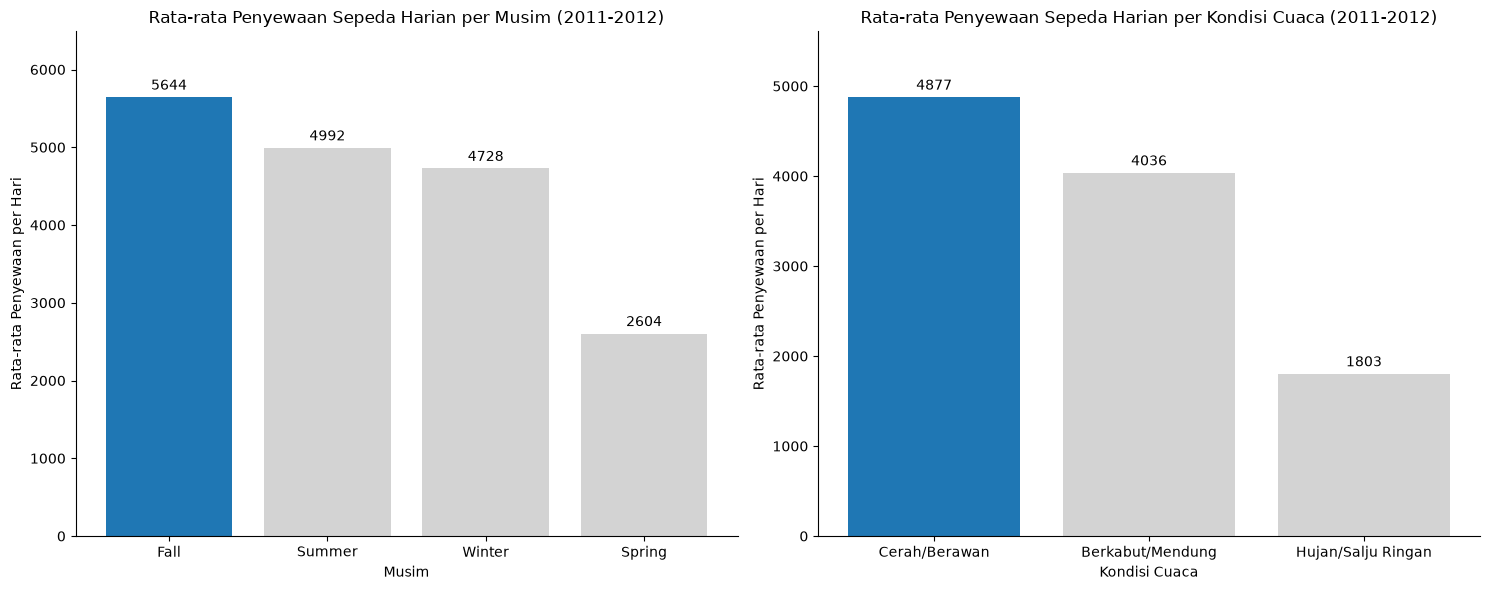

In [26]:
# Hitung rata-rata cnt per musim dan per cuaca, urutkan dari tertinggi
rata_season = day_df.groupby("season")["cnt"].mean().sort_values(ascending=False)
rata_cuaca = day_df.groupby("weathersit")["cnt"].mean().sort_values(ascending=False)

# Warna: biru tua untuk batang tertinggi, abu-abu muda untuk sisanya
warna_season = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(rata_season))]
warna_cuaca = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(rata_cuaca))]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Grafik kiri: rata-rata per musim
bar1 = axes[0].bar(rata_season.index, rata_season.values, color=warna_season)
axes[0].bar_label(bar1, fmt="%.0f", padding=3)
axes[0].set_ylim(0, rata_season.max() * 1.15)
axes[0].set_title("Rata-rata Penyewaan Sepeda Harian per Musim (2011-2012)")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Penyewaan per Hari")

# Grafik kanan: rata-rata per kondisi cuaca
bar2 = axes[1].bar(rata_cuaca.index, rata_cuaca.values, color=warna_cuaca)
axes[1].bar_label(bar2, fmt="%.0f", padding=3)
axes[1].set_ylim(0, rata_cuaca.max() * 1.15)
axes[1].set_title("Rata-rata Penyewaan Sepeda Harian per Kondisi Cuaca (2011-2012)")
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Penyewaan per Hari")

sns.despine(fig=fig)  # hilangkan garis bingkai atas dan kanan
plt.tight_layout()
plt.show()

**Insight:**
- Rata-rata penyewaan harian tertinggi ada di musim **Fall** (sekitar 5.644 sepeda per hari). Musim **Spring** paling rendah (sekitar 2.604), atau sekitar 54% lebih rendah dari Fall. Summer (sekitar 4.992) dan Winter (sekitar 4.728) ada di tengah.
- Berdasarkan cuaca, hari **Cerah/Berawan** menghasilkan rata-rata sekitar 4.877 sepeda per hari, sedangkan **Hujan/Salju Ringan** hanya sekitar 1.803, turun sekitar 63%.
- Penurunan terbesar disebabkan oleh **cuaca Hujan/Salju Ringan**, karena selisihnya (sekitar 63%) lebih besar dibanding selisih antar musim (sekitar 54%). Dari sisi musim, penurunan terbesar terjadi di **Spring**.
- Total penyewaan per kelompok bisa dilihat pada tabel agregasi di bagian EDA.

### Pertanyaan 2: Pola penyewaan per jam pada Hari Kerja dan Akhir Pekan/Libur

In [27]:
# Rata-rata cnt, registered, casual per jam untuk tiap jenis hari
cnt_jam = hour_df.groupby(["hr", "workingday"])["cnt"].mean().unstack()
reg_jam = hour_df.groupby(["hr", "workingday"])["registered"].mean().unstack()
cas_jam = hour_df.groupby(["hr", "workingday"])["casual"].mean().unstack()

# Tabel jam puncak dan jam terendah untuk setiap kombinasi
baris_ringkasan = []
for nama_tipe, tabel in [("Total (cnt)", cnt_jam), ("Registered", reg_jam), ("Casual", cas_jam)]:
    for jenis_hari in ["Hari Kerja", "Akhir Pekan/Libur"]:
        baris_ringkasan.append({
            "Tipe Pengguna": nama_tipe,
            "Jenis Hari": jenis_hari,
            "Jam Puncak": tabel[jenis_hari].idxmax(),
            "Rata-rata Puncak": round(tabel[jenis_hari].max(), 1),
            "Jam Terendah": tabel[jenis_hari].idxmin(),
            "Rata-rata Terendah": round(tabel[jenis_hari].min(), 1)
        })
ringkasan_jam = pd.DataFrame(baris_ringkasan)
ringkasan_jam

,Tipe Pengguna,Jenis Hari,Jam Puncak,Rata-rata Puncak,Jam Terendah,Rata-rata Terendah
0,Total (cnt),Hari Kerja,17,525.3,3,4.9
1,Total (cnt),Akhir Pekan/Libur,13,372.7,4,8.3
2,Registered,Hari Kerja,17,468.4,3,4.0
3,Registered,Akhir Pekan/Libur,12,240.0,4,6.0
4,Casual,Hari Kerja,17,56.9,4,0.8
5,Casual,Akhir Pekan/Libur,14,139.6,5,1.7


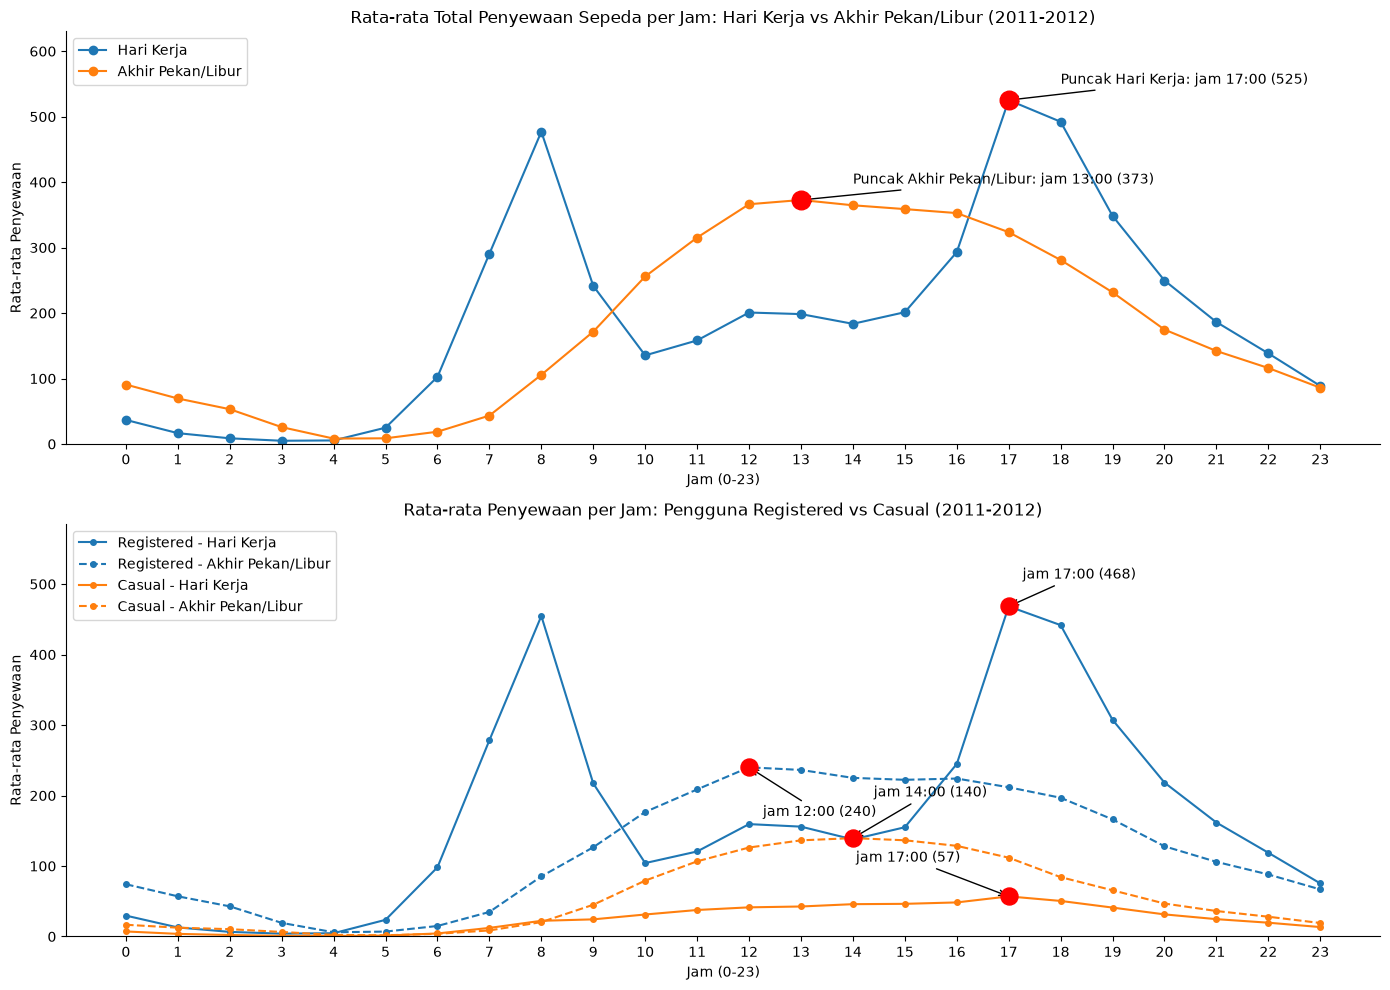

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Grafik atas: total penyewaan per jam, Hari Kerja vs Akhir Pekan/Libur
warna_hari = {"Hari Kerja": "#1f77b4", "Akhir Pekan/Libur": "#ff7f0e"}
for jenis_hari in ["Hari Kerja", "Akhir Pekan/Libur"]:
    axes[0].plot(cnt_jam.index, cnt_jam[jenis_hari], marker="o", color=warna_hari[jenis_hari], label=jenis_hari)
    jam_puncak = cnt_jam[jenis_hari].idxmax()
    nilai_puncak = cnt_jam[jenis_hari].max()
    axes[0].scatter(jam_puncak, nilai_puncak, s=180, color="red", zorder=5)  # titik puncak
    axes[0].annotate(f"Puncak {jenis_hari}: jam {jam_puncak:02d}:00 ({nilai_puncak:.0f})",
                     xy=(jam_puncak, nilai_puncak), xytext=(jam_puncak + 1, nilai_puncak + 25),
                     arrowprops=dict(arrowstyle="->"))
axes[0].set_title("Rata-rata Total Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Libur (2011-2012)")
axes[0].set_xlabel("Jam (0-23)")
axes[0].set_ylabel("Rata-rata Penyewaan")
axes[0].set_xticks(range(0, 24))
axes[0].set_ylim(0, cnt_jam.max().max() * 1.2)
axes[0].legend()

# Grafik bawah: pola jam registered vs casual pada hari kerja dan akhir pekan
gaya = [("Registered", "Hari Kerja", reg_jam, "#1f77b4", "-", (10, 20)),
        ("Registered", "Akhir Pekan/Libur", reg_jam, "#1f77b4", "--", (10, -35)),
        ("Casual", "Hari Kerja", cas_jam, "#ff7f0e", "-", (-110, 25)),
        ("Casual", "Akhir Pekan/Libur", cas_jam, "#ff7f0e", "--", (15, 30))]
for tipe, jenis_hari, tabel, warna, garis, offset in gaya:
    axes[1].plot(tabel.index, tabel[jenis_hari], color=warna, linestyle=garis, marker="o", markersize=4,
                 label=f"{tipe} - {jenis_hari}")
    jam_puncak = tabel[jenis_hari].idxmax()
    nilai_puncak = tabel[jenis_hari].max()
    axes[1].scatter(jam_puncak, nilai_puncak, s=150, color="red", zorder=5)  # titik puncak
    axes[1].annotate(f"jam {jam_puncak:02d}:00 ({nilai_puncak:.0f})", xy=(jam_puncak, nilai_puncak),
                     xytext=offset, textcoords="offset points", arrowprops=dict(arrowstyle="->"))
axes[1].set_title("Rata-rata Penyewaan per Jam: Pengguna Registered vs Casual (2011-2012)")
axes[1].set_xlabel("Jam (0-23)")
axes[1].set_ylabel("Rata-rata Penyewaan")
axes[1].set_xticks(range(0, 24))
axes[1].set_ylim(0, reg_jam.max().max() * 1.25)
axes[1].legend()

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

**Insight:**
- **Hari Kerja** punya dua puncak yang jelas, yaitu pagi sekitar **jam 08:00** dan sore sekitar **jam 17:00**. Puncak tertinggi ada di jam 17:00. Pola ini cocok dengan jam berangkat dan pulang kerja atau sekolah.
- **Akhir Pekan/Libur** punya satu puncak lebar di siang hari, sekitar jam 11:00 sampai 16:00, dan tidak ada lonjakan tajam seperti di hari kerja.
- Pengguna **registered** mengikuti pola komuter. Pada hari kerja puncaknya di jam 08:00 dan 17:00, sedangkan pada akhir pekan bergeser ke siang hari.
- Pengguna **casual** punya pola yang sangat berbeda. Penyewaannya kecil di hari kerja dan naik jauh pada akhir pekan dengan puncak di siang sampai sore hari. Jadi pengguna casual lebih banyak memakai sepeda untuk rekreasi.
- Titik terendah terjadi pada dini hari, sekitar jam 03:00 sampai 05:00, baik di hari kerja maupun akhir pekan, dengan rata-rata penyewaan hanya beberapa sepeda per jam. Nilai tepatnya ada pada tabel ringkasan di atas.

## Analisis Lanjutan (Clustering Tanpa Machine Learning: Manual Grouping & Binning)

Tahap ini bertujuan membuat segmentasi operasional tanpa model machine learning, memakai dua teknik sederhana:

- **Manual Grouping** mengelompokkan data dengan aturan yang kita tentukan sendiri. Di sini jam (`hr`) dikelompokkan menjadi `waktu_hari` agar tim operasional bisa membuat jadwal per waktu, bukan per jam.
- **Binning** membagi data numerik ke dalam rentang tertentu. Di sini `temp_celsius` dibagi menjadi `kategori_suhu` dan `cnt` dibagi menjadi `kategori_permintaan`.

Aturan pengelompokannya:

| Kolom baru | Aturan |
|---|---|
| `waktu_hari` | Pagi (jam 05 sampai 10), Siang (jam 11 sampai 14), Sore (jam 15 sampai 18), Malam (jam 19 sampai 04) |
| `kategori_suhu` | Dingin (di bawah 15°C), Sejuk (15°C sampai 25°C), Panas (di atas 25°C) |
| `kategori_permintaan` | Sepi, Normal, Ramai, dibagi dengan `pd.qcut()` sehingga masing-masing berisi sekitar sepertiga data berdasarkan `cnt` |

In [29]:
# Manual Grouping: kelompokkan jam menjadi waktu_hari
kondisi_waktu = [
    (hour_df["hr"] >= 5) & (hour_df["hr"] <= 10),
    (hour_df["hr"] >= 11) & (hour_df["hr"] <= 14),
    (hour_df["hr"] >= 15) & (hour_df["hr"] <= 18)
]
pilihan_waktu = ["Pagi", "Siang", "Sore"]
hour_df["waktu_hari"] = np.select(kondisi_waktu, pilihan_waktu, default="Malam")  # jam 19-04 = Malam

# Binning suhu dengan pd.cut (batas bawah 14.999999 agar tepat 15 masuk kelompok Sejuk)
hour_df["kategori_suhu"] = pd.cut(hour_df["temp_celsius"],
                                  bins=[-np.inf, 14.999999, 25, np.inf],
                                  labels=["Dingin", "Sejuk", "Panas"])

# Binning tingkat permintaan dengan pd.qcut (3 kelompok berukuran hampir sama)
hour_df["kategori_permintaan"] = pd.qcut(hour_df["cnt"], q=3, labels=["Sepi", "Normal", "Ramai"])

hour_df[["hr", "waktu_hari", "temp_celsius", "kategori_suhu", "cnt", "kategori_permintaan"]].head(10)

,hr,waktu_hari,temp_celsius,kategori_suhu,cnt,kategori_permintaan
0,0,Malam,9.84,Dingin,16,Sepi
1,1,Malam,9.02,Dingin,40,Sepi
2,2,Malam,9.02,Dingin,32,Sepi
3,3,Malam,9.84,Dingin,13,Sepi
4,4,Malam,9.84,Dingin,1,Sepi
5,5,Pagi,9.84,Dingin,1,Sepi
6,6,Pagi,9.02,Dingin,2,Sepi
7,7,Pagi,8.20,Dingin,3,Sepi
8,8,Pagi,9.84,Dingin,8,Sepi
9,9,Pagi,13.12,Dingin,14,Sepi


In [30]:
# Tabel agregasi rata-rata penyewaan per waktu_hari
agg_waktu = hour_df.groupby("waktu_hari").agg(
    jumlah_jam=("cnt", "count"),
    rata_cnt=("cnt", "mean"),
    rata_registered=("registered", "mean"),
    rata_casual=("casual", "mean"),
    total_cnt=("cnt", "sum")
).sort_values("rata_cnt", ascending=False).round(1)
agg_waktu

,jumlah_jam,rata_cnt,rata_registered,rata_casual,total_cnt
waktu_hari,,,,,
Sore,2917,362.5,291.5,71.0,1057529
Siang,2913,239.0,170.1,68.9,696305
Pagi,4350,177.1,157.7,19.3,770260
Malam,7199,106.8,89.0,17.8,768585


In [31]:
# Tabel agregasi rata-rata penyewaan per kategori_suhu
agg_suhu = hour_df.groupby("kategori_suhu", observed=True).agg(
    jumlah_jam=("cnt", "count"),
    rata_cnt=("cnt", "mean"),
    rata_registered=("registered", "mean"),
    rata_casual=("casual", "mean"),
    total_cnt=("cnt", "sum")
).sort_values("rata_cnt", ascending=False).round(1)
agg_suhu

,jumlah_jam,rata_cnt,rata_registered,rata_casual,total_cnt
kategori_suhu,,,,,
Panas,5835,268.7,207.2,61.4,1567654
Sejuk,6103,190.1,156.1,34.0,1160028
Dingin,5441,103.8,93.9,9.9,564997


In [32]:
# Batas nilai cnt untuk setiap kategori_permintaan
agg_permintaan = hour_df.groupby("kategori_permintaan", observed=True)["cnt"].agg(["count", "min", "max", "mean"]).round(1)
agg_permintaan

,count,min,max,mean
kategori_permintaan,,,,
Sepi,5797,1,70,25.1
Normal,5823,71,225,144.3
Ramai,5759,226,977,400.6


In [33]:
# Persentase kategori_permintaan pada setiap waktu_hari (baris berjumlah 100%)
pd.crosstab(hour_df["waktu_hari"], hour_df["kategori_permintaan"], normalize="index").mul(100).round(1)

kategori_permintaan,Sepi,Normal,Ramai
waktu_hari,,,
Malam,54.5,29.7,15.8
Pagi,34.8,35.9,29.4
Siang,8.0,47.0,45.0
Sore,4.5,25.9,69.6


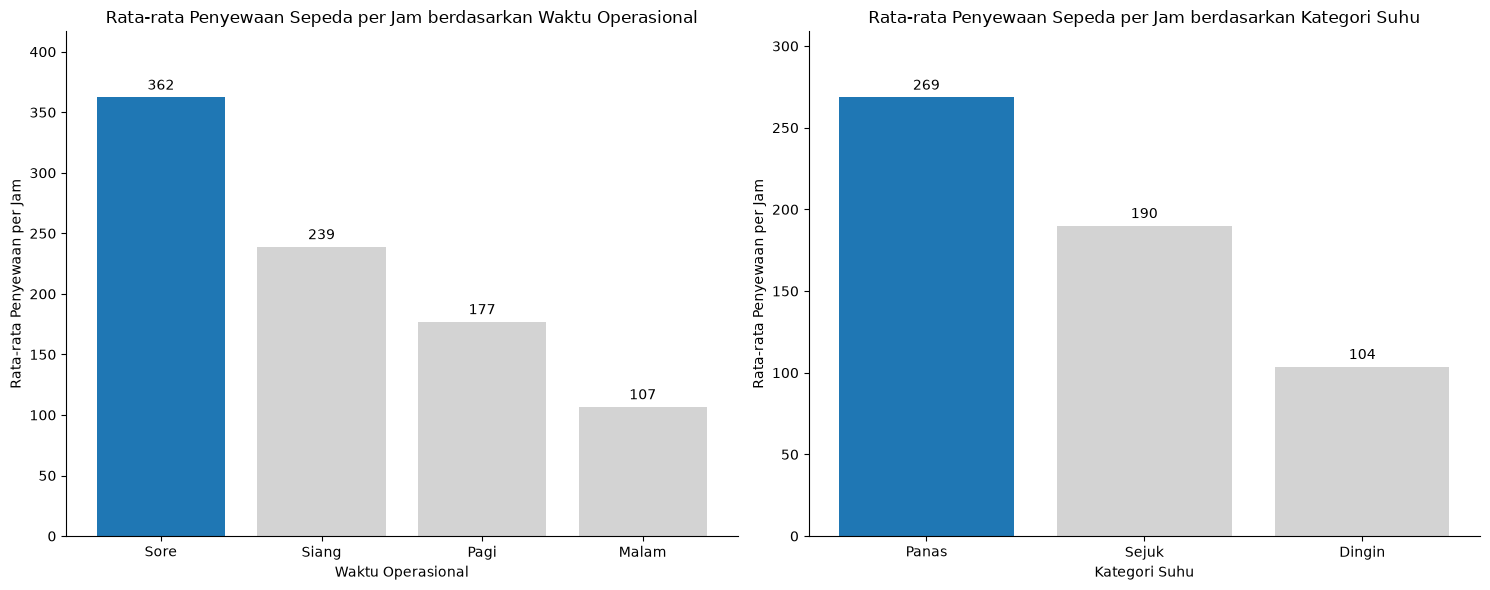

In [34]:
# Bar chart rata-rata penyewaan per waktu_hari dan per kategori_suhu
rata_waktu = agg_waktu["rata_cnt"].sort_values(ascending=False)
rata_suhu = agg_suhu["rata_cnt"].sort_values(ascending=False)

warna_waktu = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(rata_waktu))]
warna_suhu = ["#1f77b4" if i == 0 else "#d3d3d3" for i in range(len(rata_suhu))]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Grafik kiri: waktu_hari
bar1 = axes[0].bar(rata_waktu.index.astype(str), rata_waktu.values, color=warna_waktu)
axes[0].bar_label(bar1, fmt="%.0f", padding=3)
axes[0].set_ylim(0, rata_waktu.max() * 1.15)
axes[0].set_title("Rata-rata Penyewaan Sepeda per Jam berdasarkan Waktu Operasional")
axes[0].set_xlabel("Waktu Operasional")
axes[0].set_ylabel("Rata-rata Penyewaan per Jam")

# Grafik kanan: kategori_suhu
bar2 = axes[1].bar(rata_suhu.index.astype(str), rata_suhu.values, color=warna_suhu)
axes[1].bar_label(bar2, fmt="%.0f", padding=3)
axes[1].set_ylim(0, rata_suhu.max() * 1.15)
axes[1].set_title("Rata-rata Penyewaan Sepeda per Jam berdasarkan Kategori Suhu")
axes[1].set_xlabel("Kategori Suhu")
axes[1].set_ylabel("Rata-rata Penyewaan per Jam")

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

In [35]:
# Simpan dataframe bersih beserta kolom baru untuk dashboard
import os
os.makedirs("dashboard", exist_ok=True)
hour_df.to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv tersimpan:", hour_df.shape)

main_data.csv tersimpan: (17379, 23)


**Insight:**
- Berdasarkan `waktu_hari`, kelompok **Sore** (jam 15 sampai 18) punya rata-rata penyewaan per jam tertinggi karena mencakup puncak jam pulang kerja di sekitar jam 17:00. Kelompok **Malam** (jam 19 sampai 04) paling rendah karena banyak jam dini hari yang sepi.
- Berdasarkan `kategori_suhu`, kelompok **Panas** (di atas 25°C) punya rata-rata penyewaan per jam tertinggi, sedangkan **Dingin** (di bawah 15°C) paling rendah. Hasil ini sejalan dengan korelasi positif antara suhu dan `cnt` di bagian EDA.
- Dengan `pd.qcut()`, jam-jam tersebut terbagi ke Sepi, Normal, dan Ramai dalam jumlah yang hampir sama. Tabel batas `cnt` menunjukkan rentang jumlah penyewaan untuk tiap kategori, dan persentase per `waktu_hari` memperlihatkan bahwa jam Sore didominasi kategori Ramai sedangkan jam Malam didominasi kategori Sepi.
- Kolom baru `waktu_hari`, `kategori_suhu`, dan `kategori_permintaan` disimpan di `dashboard/main_data.csv` supaya bisa dipakai di dashboard Streamlit.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Rata-rata penyewaan harian selama 2011 sampai 2012 adalah sekitar 4.504 sepeda, dengan total sekitar 3,29 juta. Musim Fall paling tinggi (sekitar 5.644 per hari) dan Spring paling rendah (sekitar 2.604 per hari, sekitar 54% lebih rendah dari Fall). Dari sisi cuaca, hari Cerah/Berawan rata-ratanya sekitar 4.877 per hari, sedangkan Hujan/Salju Ringan hanya sekitar 1.803 per hari, turun sekitar 63%. Jadi penurunan penyewaan terbesar disebabkan oleh cuaca Hujan/Salju Ringan, dan dari sisi musim terjadi pada Spring.
- **Conclusion pertanyaan 2:** Pada Hari Kerja puncak penyewaan terjadi pada jam 08:00 dan 17:00, dengan puncak tertinggi di jam 17:00. Pada Akhir Pekan/Libur puncaknya melebar di siang hari, sekitar jam 11:00 sampai 16:00. Pengguna registered mengikuti pola komuter, sedangkan pengguna casual jauh lebih aktif di akhir pekan. Titik terendah ada pada dini hari, sekitar jam 03:00 sampai 05:00.
- **Conclusion analisis lanjutan:** Kelompok waktu Sore punya rata-rata penyewaan per jam tertinggi dan Malam terendah. Pada kategori suhu, Panas (di atas 25°C) tertinggi dan Dingin (di bawah 15°C) terendah. Segmentasi ini memperlihatkan bahwa permintaan tertinggi ada saat sore hari dan suhu hangat, sehingga bisa dipakai sebagai dasar jadwal operasional.

**Rekomendasi Action Item:**
1. **Penjadwalan stok sepeda di stasiun.** Pada Hari Kerja, tambah stok dan siapkan petugas redistribusi sebelum jam 08:00 dan jam 17:00 di stasiun dekat kawasan kerja, kampus, dan transportasi umum. Pada Akhir Pekan/Libur, alihkan stok ke stasiun di area rekreasi untuk rentang jam 12:00 sampai 16:00.
2. **Strategi pemeliharaan armada.** Lakukan perawatan dan servis besar pada musim Spring dan pada jam Malam (terutama dini hari), karena permintaan paling rendah sehingga dampaknya ke pengguna paling kecil. Siapkan juga jadwal servis setelah hari hujan.
3. **Program promo konversi casual ke registered.** Pengguna casual paling banyak muncul di akhir pekan, jadi tawarkan promo langganan lewat aplikasi atau stasiun pada akhir pekan, terutama di musim Fall dan Summer saat penyewaan sedang tinggi. Contohnya diskon bulan pertama atau paket langganan akhir pekan.